# Quantum Voting Protocol — Numerical Experiments

**Paper:** Ali Emre, A., & Ammar, D. (2025). *Quantum Voting Protocol for Centralized and Distributed Voting Based on Phase-Flip Counting.* [arXiv:2510.15243](https://arxiv.org/abs/2510.15243)

This notebook reproduces and extends the numerical experiments from **Section V** of the paper.

## Scenarios per Example

| # | Scenario | Description |
|---|----------|-------------|
| S0 | **Ideal** | Statevector (exact) vs finite sampling |
| S1 | **Noise** | Depolarizing channel on candidate qubits |
| S2 | **Dishonest Voter** | One voter applies a malicious gate |
| S3 | **Sampling Convergence** | Shot count sweep to show Hoeffding convergence |

---


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from quantum_voting import QuantumVotingProtocol
from quantum_voting.experiments import (
    example1_4voters_2candidates,
    example2_8voters_3candidates,
)
from quantum_voting.visualization import (
    plot_comparison, plot_scenarios, plot_convergence,
)

SHOTS = 20_000  # default shot count for sampling experiments
print("✓ All modules imported successfully.")


✓ All modules imported successfully.


In [2]:
def print_results_table(proto, theo, sim, valid=None, total=None, title=""):
    """Formatted comparison table for a single scenario."""
    names = proto.candidate_names + (["Spoiled"] if "Spoiled" in sim else [])
    print(f"\n{'═' * 60}")
    print(f" {title}")
    print(f"{'═' * 60}")
    if valid is not None:
        print(f" Post-selection: {valid:,} / {total:,} valid shots "
              f"({valid/total*100:.1f}%)")
    print(f"┌──────────────────┬───────────────┬───────────────┐")
    print(f"│    Candidate     │  Statevector  │  Simulation   │")
    print(f"├──────────────────┼───────────────┼───────────────┤")
    for name in names:
        t = theo.get(name, 0) * 100
        s = sim.get(name, 0) * 100
        t_str = f"{t:9.4f}%" if name in theo else "    —    "
        print(f"│ {name:16s} │  {t_str:11s}  │  {s:9.4f}%  │")
    print(f"└──────────────────┴───────────────┴───────────────┘")


---

# Example 1: 4 Voters, 2 Candidates (Blue vs Red)

**Paper Section V-A**

- **Candidate state:** Bell state $|\psi_{\text{cands}}\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$
- **Blue vote** → phase-flip $|11\rangle$: $|00\rangle - |11\rangle$
- **Red vote** → phase-flip $|00\rangle$: $-|00\rangle + |11\rangle$
- **Vote distribution:** V0 → Blue, V1 → Red, V2 → Blue, V3 → Red
- **Expected:** $P(\text{Blue}) = P(\text{Red}) = 50\%$


## Scenario 0 — Ideal (No Noise, Honest Voters)

In [3]:
proto1 = example1_4voters_2candidates()
print(proto1.info())

theo1, post_prob1 = proto1.run_statevector()
sim1, valid1, total1 = proto1.run_shots(shots=SHOTS)

print_results_table(proto1, theo1, sim1, valid1, total1,
                    "EXAMPLE 1 — S0: IDEAL")


Voters       : 4 (2 ID qubits)
Candidates   : 2 (2 cand. qubits)
Total qubits : 5
Wires        : ID=[0, 1], Ctrl=2, Cand=[3, 4]
Votes        : V0→Blue, V1→Red, V2→Blue, V3→Red
Scenario     : ideal

════════════════════════════════════════════════════════════
 EXAMPLE 1 — S0: IDEAL
════════════════════════════════════════════════════════════
 Post-selection: 10,065 / 20,000 valid shots (50.3%)
┌──────────────────┬───────────────┬───────────────┐
│    Candidate     │  Statevector  │  Simulation   │
├──────────────────┼───────────────┼───────────────┤
│ Blue             │    50.0000%   │    50.4620%  │
│ Red              │    50.0000%   │    49.5380%  │
└──────────────────┴───────────────┴───────────────┘


  → Figure saved to figures/ex1_s0_ideal.png


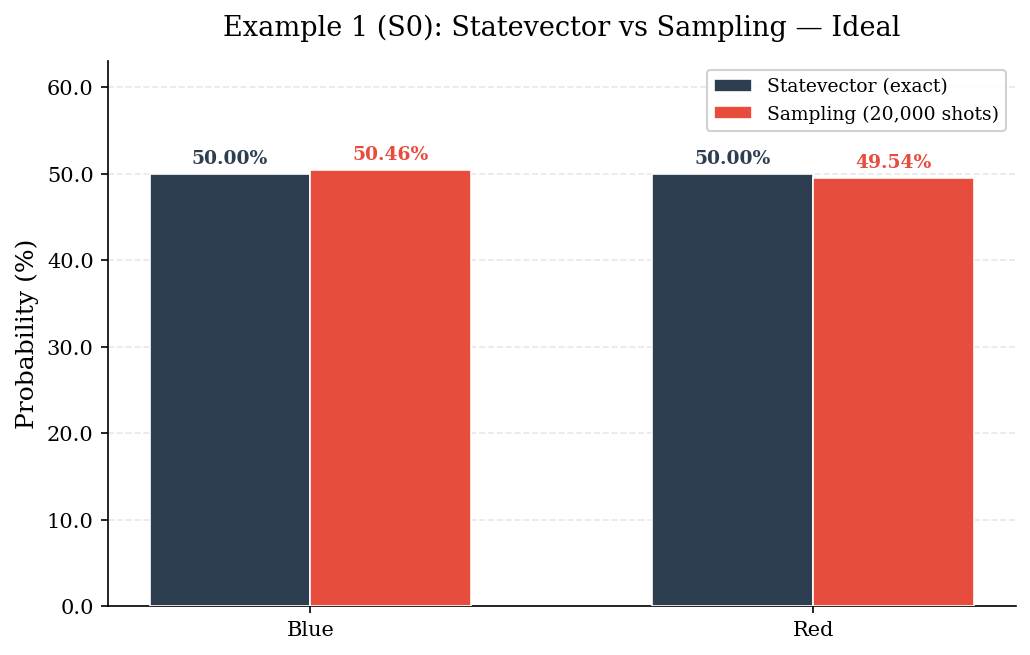

In [4]:
fig = plot_comparison(
    theo1, sim1, proto1.candidate_names,
    title="Example 1 (S0): Statevector vs Sampling — Ideal",
    save_path="figures/ex1_s0_ideal.png",
    shots_label=f"{SHOTS:,}",
)
plt.show()


## Scenario 1 — Depolarizing Noise

A depolarizing channel with probability $p$ is applied to each candidate qubit after voting. This simulates decoherence in the quantum channel and should cause:
- Probability mass to leak into invalid basis states (e.g. $|11\rangle$ for 2 candidates)
- Distortion of the vote distribution proportional to $p$


  Noise p=5%      → Blue:  46.35%, Red:  47.19%, Spoiled:  6.46%  (valid: 9986/20000)
  Noise p=10%     → Blue:  43.96%, Red:  43.90%, Spoiled: 12.13%  (valid: 10038/20000)
  Noise p=20%     → Blue:  38.61%, Red:  38.37%, Spoiled: 23.02%  (valid: 9992/20000)


  → Figure saved to figures/ex1_s1_noise.png


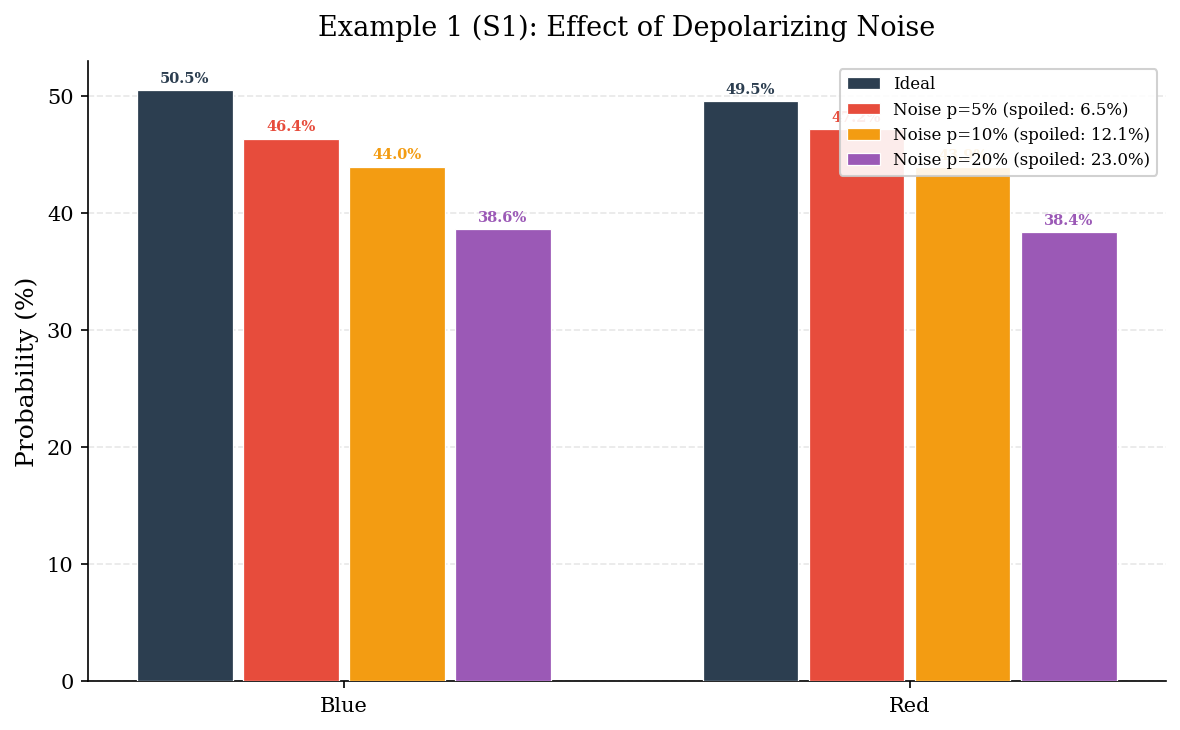

In [5]:
noise_levels_1 = [0.05, 0.10, 0.20]
scenario_results_1_noise = [("Ideal", sim1)]

for nl in noise_levels_1:
    proto_n = QuantumVotingProtocol(
        n_voters=4, n_candidates=2,
        candidate_names=["Blue", "Red"],
        candidate_basis_map={0: [1, 1], 1: [0, 0]},
        candidate_state=np.array([1, 0, 0, 1]) / np.sqrt(2),
        vote_distribution=[0, 1, 0, 1],
        noise_level=nl,
    )
    sim_n, valid_n, total_n = proto_n.run_shots(shots=SHOTS)
    label = f"Noise p={nl:.0%}"
    scenario_results_1_noise.append((label, sim_n))
    print(f"  {label:15s} → Blue: {sim_n.get('Blue',0)*100:6.2f}%, "
          f"Red: {sim_n.get('Red',0)*100:6.2f}%, "
          f"Spoiled: {sim_n.get('Spoiled',0)*100:5.2f}%  "
          f"(valid: {valid_n}/{total_n})")

fig = plot_scenarios(
    scenario_results_1_noise, proto1.candidate_names,
    title="Example 1 (S1): Effect of Depolarizing Noise",
    save_path="figures/ex1_s1_noise.png",
)
plt.show()


## Scenario 2 — Dishonest Voter

Voter 0 (who should vote Blue) instead applies an arbitrary malicious unitary $R_Y(\pi/3) \otimes R_Y(\pi/4)$. This should:
- Distort the probability distribution
- Potentially generate spoiled votes
- Demonstrate the protocol's sensitivity to tampering


  Dishonest [0] → Blue:  32.53%, Red:  67.15%, Spoiled:  0.32%
  Dishonest [0, 1] → Blue:  50.46%, Red:  48.59%, Spoiled:  0.96%
  Dishonest [0, 1, 2] → Blue:   0.00%, Red:  97.97%, Spoiled:  2.03%


  → Figure saved to figures/ex1_s2_dishonest.png


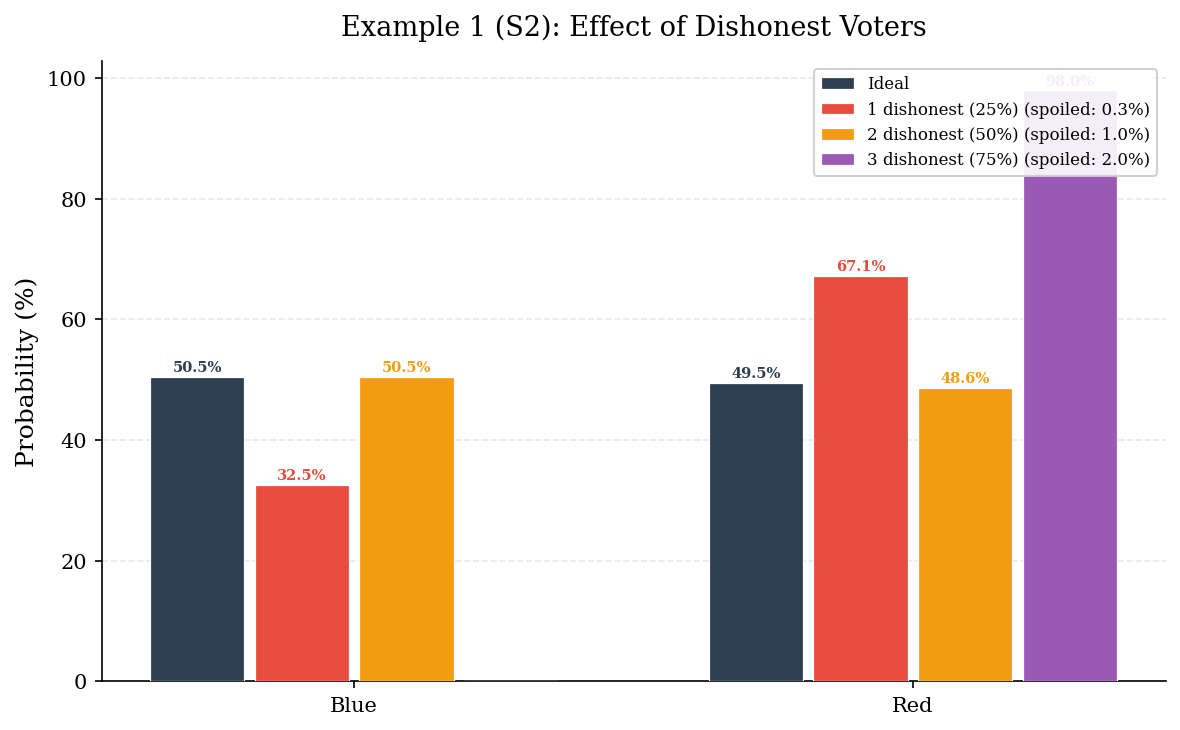

In [6]:
dishonest_indices_1 = [[0], [0, 1], [0, 1, 2]]
scenario_results_1_dish = [("Ideal", sim1)]

for d_idxs in dishonest_indices_1:
    proto_d = QuantumVotingProtocol(
        n_voters=4, n_candidates=2,
        candidate_names=["Blue", "Red"],
        candidate_basis_map={0: [1, 1], 1: [0, 0]},
        candidate_state=np.array([1, 0, 0, 1]) / np.sqrt(2),
        vote_distribution=[0, 1, 0, 1],
        dishonest_voters=set(d_idxs),
    )
    sim_d, valid_d, total_d = proto_d.run_shots(shots=SHOTS)
    pct = len(d_idxs) / 4 * 100
    label = f"{len(d_idxs)} dishonest ({pct:.0f}%)"
    scenario_results_1_dish.append((label, sim_d))
    print(f"  Dishonest {d_idxs} → Blue: {sim_d.get('Blue',0)*100:6.2f}%, "
          f"Red: {sim_d.get('Red',0)*100:6.2f}%, "
          f"Spoiled: {sim_d.get('Spoiled',0)*100:5.2f}%")

fig = plot_scenarios(
    scenario_results_1_dish, proto1.candidate_names,
    title="Example 1 (S2): Effect of Dishonest Voters",
    save_path="figures/ex1_s2_dishonest.png",
)
plt.show()


## Scenario 3 — Sampling Convergence (Tie-Breaking Resolution)

Blue and Red have exactly 50%–50% probability. With finite shots, statistical fluctuations can cause one candidate to appear ahead. This experiment sweeps the shot count to show how the **Hoeffding bound** governs convergence:

$$P\bigl(|\hat{p} - p| \geq \epsilon\bigr) \leq 2\exp(-2N\epsilon^2)$$


Shot Count   │  Blue     │  Red      │  |Blue-Red|
─────────────┼───────────┼───────────┼────────────
        500  │   53.36%  │   46.64%  │   6.72%
      2,000  │   49.60%  │   50.40%  │   0.80%


      5,000  │   50.46%  │   49.54%  │   0.92%
     20,000  │   49.79%  │   50.21%  │   0.42%
    100,000  │   50.26%  │   49.74%  │   0.53%
─────────────┼───────────┼───────────┼────────────
  Theory     │  50.00%   │  50.00%   │   0.00%


  → Figure saved to figures/ex1_s3_convergence.png


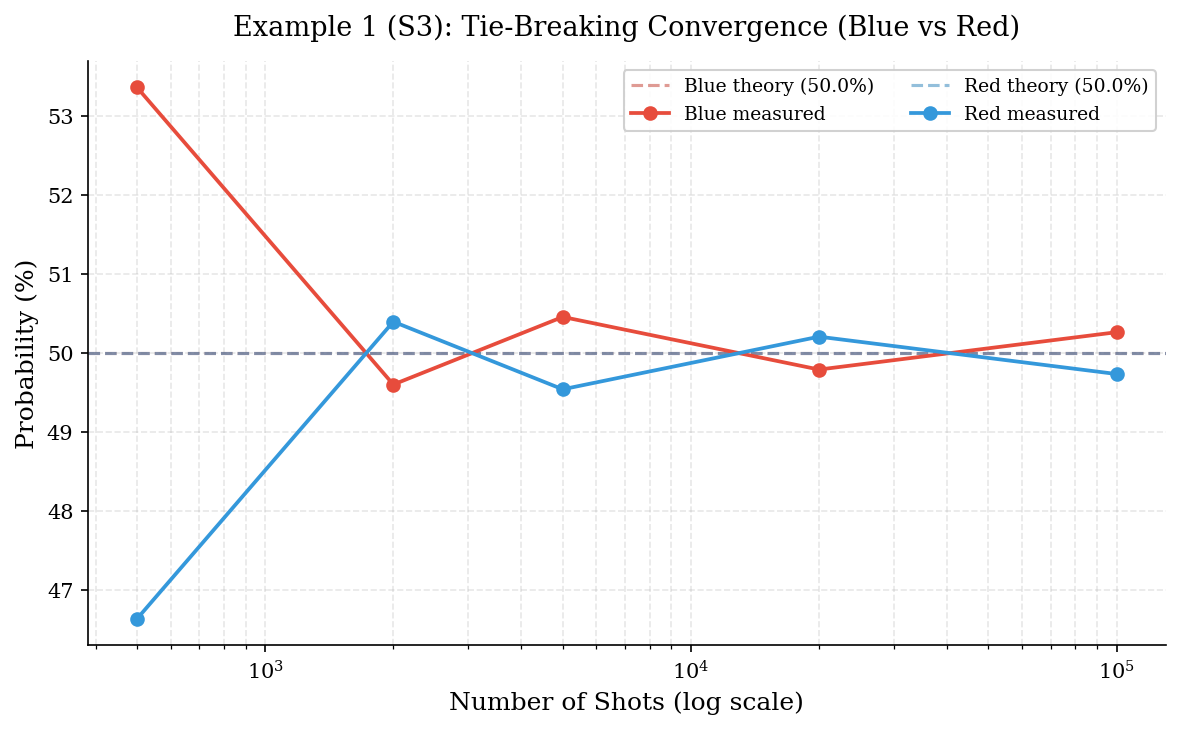

In [7]:
shot_counts_1 = [500, 2_000, 5_000, 20_000, 100_000]
histories_1 = {n: [] for n in proto1.candidate_names}
theo_exact_1 = proto1.theoretical_probabilities

print("Shot Count   │  Blue     │  Red      │  |Blue-Red|")
print("─────────────┼───────────┼───────────┼────────────")

for s in shot_counts_1:
    p, v, _ = proto1.run_shots(shots=s)
    for name in proto1.candidate_names:
        histories_1[name].append(p.get(name, 0))
    diff = abs(p.get("Blue", 0) - p.get("Red", 0)) * 100
    print(f"  {s:>9,}  │  {p.get('Blue',0)*100:6.2f}%  │  "
          f"{p.get('Red',0)*100:6.2f}%  │  {diff:5.2f}%")

print("─────────────┼───────────┼───────────┼────────────")
print(f"  Theory     │  50.00%   │  50.00%   │   0.00%")

fig = plot_convergence(
    shot_counts_1, histories_1, theo_exact_1, proto1.candidate_names,
    title="Example 1 (S3): Tie-Breaking Convergence (Blue vs Red)",
    save_path="figures/ex1_s3_convergence.png",
)
plt.show()


---

# Example 2: 8 Voters, 3 Candidates

**Paper Section V-B**

- **Candidate state:** W-like state $|\psi_{\text{cands}}\rangle = \frac{1}{\sqrt{3}}(|00\rangle + |01\rangle + |10\rangle)$
- **Vote distribution:** Voters 0,3,5 → C0; Voters 1,4,6 → C1; Voters 2,7 → C2
- **Expected:** $P(C_0) = P(C_1) = 37.5\%$, $\;P(C_2) = 25.0\%$


## Scenario 0 — Ideal (No Noise, Honest Voters)

In [8]:
proto2 = example2_8voters_3candidates()
print(proto2.info())

theo2, post_prob2 = proto2.run_statevector()
sim2, valid2, total2 = proto2.run_shots(shots=SHOTS)

print_results_table(proto2, theo2, sim2, valid2, total2,
                    "EXAMPLE 2 — S0: IDEAL")


Voters       : 8 (3 ID qubits)
Candidates   : 3 (2 cand. qubits)
Total qubits : 6
Wires        : ID=[0, 1, 2], Ctrl=3, Cand=[4, 5]
Votes        : V0→Candidate 0, V1→Candidate 1, V2→Candidate 2, V3→Candidate 0, V4→Candidate 1, V5→Candidate 0, V6→Candidate 1, V7→Candidate 2
Scenario     : ideal

════════════════════════════════════════════════════════════
 EXAMPLE 2 — S0: IDEAL
════════════════════════════════════════════════════════════
 Post-selection: 6,587 / 20,000 valid shots (32.9%)
┌──────────────────┬───────────────┬───────────────┐
│    Candidate     │  Statevector  │  Simulation   │
├──────────────────┼───────────────┼───────────────┤
│ Candidate 0      │    37.5000%   │    38.1509%  │
│ Candidate 1      │    37.5000%   │    37.1186%  │
│ Candidate 2      │    25.0000%   │    24.7305%  │
└──────────────────┴───────────────┴───────────────┘


  → Figure saved to figures/ex2_s0_ideal.png


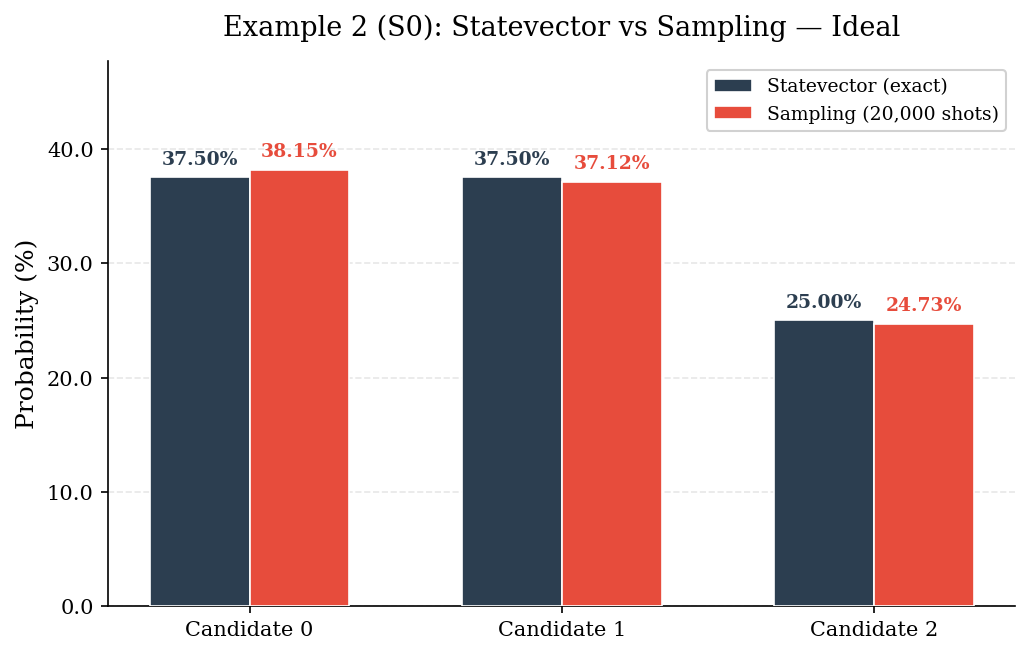

In [9]:
fig = plot_comparison(
    theo2, sim2, proto2.candidate_names,
    title="Example 2 (S0): Statevector vs Sampling — Ideal",
    save_path="figures/ex2_s0_ideal.png",
    shots_label=f"{SHOTS:,}",
)
plt.show()


## Scenario 1 — Depolarizing Noise

A depolarizing channel with probability $p$ is applied to each candidate qubit. With 3 candidates encoded on 2 qubits, the unused basis state $|11\rangle$ becomes a "spoiled vote" indicator — noise leaks probability into $|11\rangle$ which is not assigned to any candidate.


  Noise p=5%      → C0:  37.90%, C1:  35.45%, C2:  24.73%, Spoiled:  1.92%
  Noise p=10%     → C0:  36.51%, C1:  34.50%, C2:  24.71%, Spoiled:  4.28%


  Noise p=20%     → C0:  36.21%, C1:  32.27%, C2:  23.93%, Spoiled:  7.60%
  → Figure saved to figures/ex2_s1_noise.png


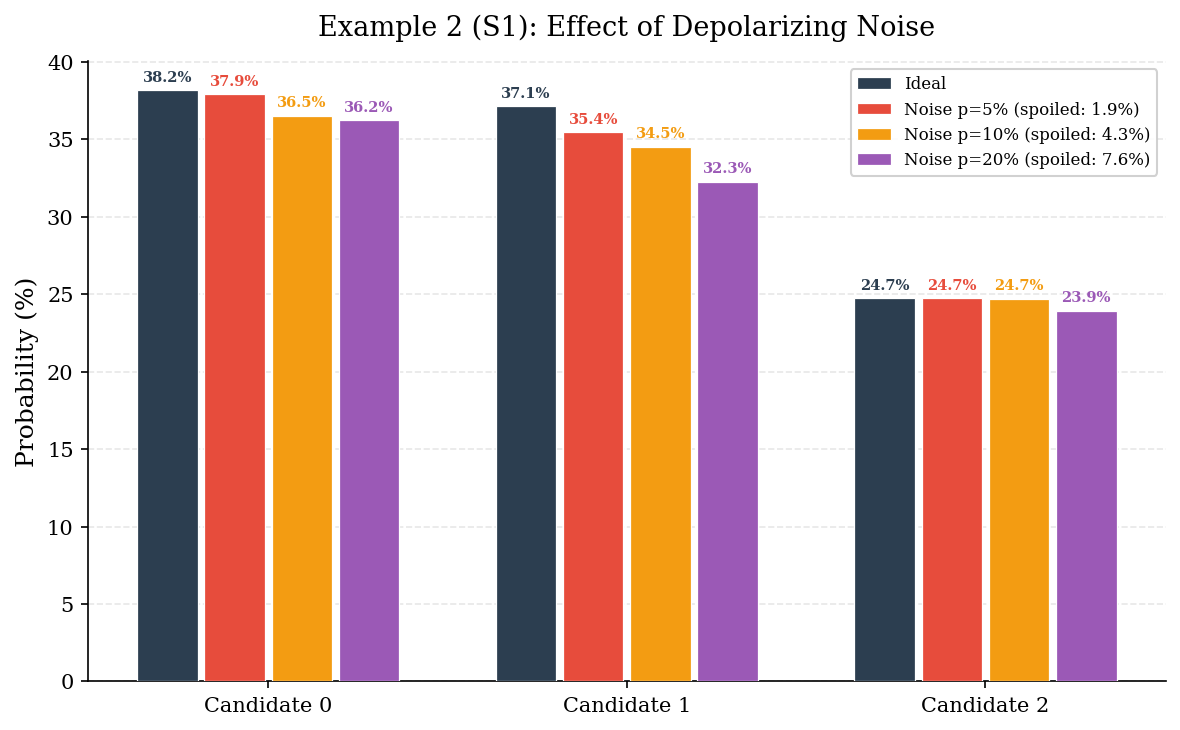

In [10]:
noise_levels_2 = [0.05, 0.10, 0.20]
scenario_results_2_noise = [("Ideal", sim2)]

for nl in noise_levels_2:
    proto_n2 = QuantumVotingProtocol(
        n_voters=8, n_candidates=3,
        candidate_names=["Candidate 0", "Candidate 1", "Candidate 2"],
        candidate_basis_map={0: [0, 0], 1: [0, 1], 2: [1, 0]},
        candidate_state=np.array([1, 1, 1, 0]) / np.sqrt(3),
        vote_distribution=[0, 1, 2, 0, 1, 0, 1, 2],
        noise_level=nl,
    )
    sim_n2, valid_n2, total_n2 = proto_n2.run_shots(shots=SHOTS)
    label = f"Noise p={nl:.0%}"
    scenario_results_2_noise.append((label, sim_n2))
    print(f"  {label:15s} → C0: {sim_n2.get('Candidate 0',0)*100:6.2f}%, "
          f"C1: {sim_n2.get('Candidate 1',0)*100:6.2f}%, "
          f"C2: {sim_n2.get('Candidate 2',0)*100:6.2f}%, "
          f"Spoiled: {sim_n2.get('Spoiled',0)*100:5.2f}%")

fig = plot_scenarios(
    scenario_results_2_noise, proto2.candidate_names,
    title="Example 2 (S1): Effect of Depolarizing Noise",
    save_path="figures/ex2_s1_noise.png",
)
plt.show()


## Scenario 2 — Dishonest Voter

We progressively increase the number of dishonest voters (who apply $R_Y(\pi/3) \otimes R_Y(\pi/4)$ instead of the correct phase-flip) to observe the degradation in tallying accuracy.


  Dishonest [0] → C0:  30.29%, C1:  39.99%, C2:  26.75%, Spoiled:  2.97%
  Dishonest [0, 1] → C0:  35.64%, C1:  28.59%, C2:  28.83%, Spoiled:  6.95%
  Dishonest [0, 1, 2, 3] → C0:  33.06%, C1:  33.69%, C2:  16.67%, Spoiled: 16.57%


  → Figure saved to figures/ex2_s2_dishonest.png


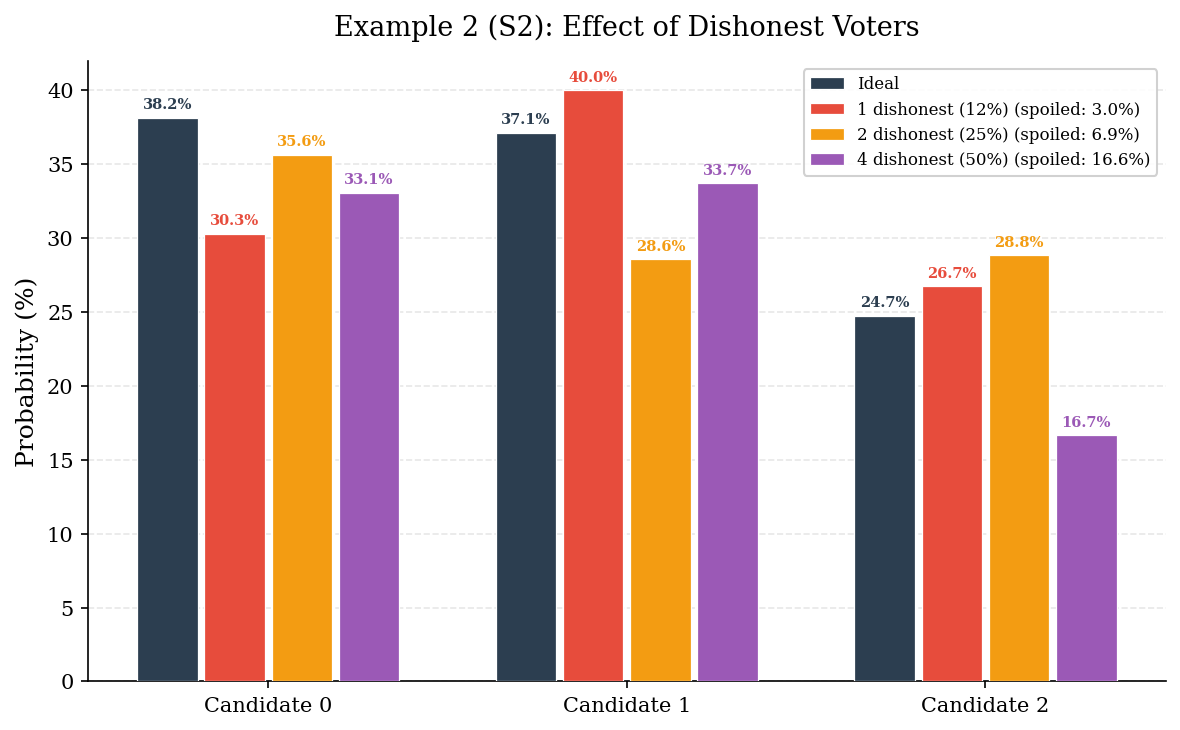

In [11]:
dishonest_indices_2 = [[0], [0, 1], [0, 1, 2, 3]]
scenario_results_2_dish = [("Ideal", sim2)]

for d_idxs in dishonest_indices_2:
    proto_d2 = QuantumVotingProtocol(
        n_voters=8, n_candidates=3,
        candidate_names=["Candidate 0", "Candidate 1", "Candidate 2"],
        candidate_basis_map={0: [0, 0], 1: [0, 1], 2: [1, 0]},
        candidate_state=np.array([1, 1, 1, 0]) / np.sqrt(3),
        vote_distribution=[0, 1, 2, 0, 1, 0, 1, 2],
        dishonest_voters=set(d_idxs),
    )
    sim_d2, valid_d2, total_d2 = proto_d2.run_shots(shots=SHOTS)
    pct = len(d_idxs) / 8 * 100
    label = f"{len(d_idxs)} dishonest ({pct:.0f}%)"
    scenario_results_2_dish.append((label, sim_d2))
    print(f"  Dishonest {d_idxs} → C0: {sim_d2.get('Candidate 0',0)*100:6.2f}%, "
          f"C1: {sim_d2.get('Candidate 1',0)*100:6.2f}%, "
          f"C2: {sim_d2.get('Candidate 2',0)*100:6.2f}%, "
          f"Spoiled: {sim_d2.get('Spoiled',0)*100:5.2f}%")

fig = plot_scenarios(
    scenario_results_2_dish, proto2.candidate_names,
    title="Example 2 (S2): Effect of Dishonest Voters",
    save_path="figures/ex2_s2_dishonest.png",
)
plt.show()


## Scenario 3 — Sampling Convergence

Candidates 0 and 1 are tied at 37.5% each. This experiment shows how many shots are needed to reliably distinguish between candidates and resolve close races.


Shot Count   │  Cand. 0   │  Cand. 1   │  Cand. 2   │  |C0-C1|
─────────────┼────────────┼────────────┼────────────┼──────────
        500  │    33.33%  │    37.91%  │    28.76%  │   4.58%
      2,000  │    38.42%  │    36.62%  │    24.96%  │   1.79%
      5,000  │    37.95%  │    35.41%  │    26.64%  │   2.53%
     20,000  │    39.28%  │    35.70%  │    25.03%  │   3.58%


    100,000  │    37.78%  │    37.31%  │    24.91%  │   0.48%
─────────────┼────────────┼────────────┼────────────┼──────────
  Theory     │    37.50%  │    37.50%  │    25.00%  │   0.00%


  → Figure saved to figures/ex2_s3_convergence.png


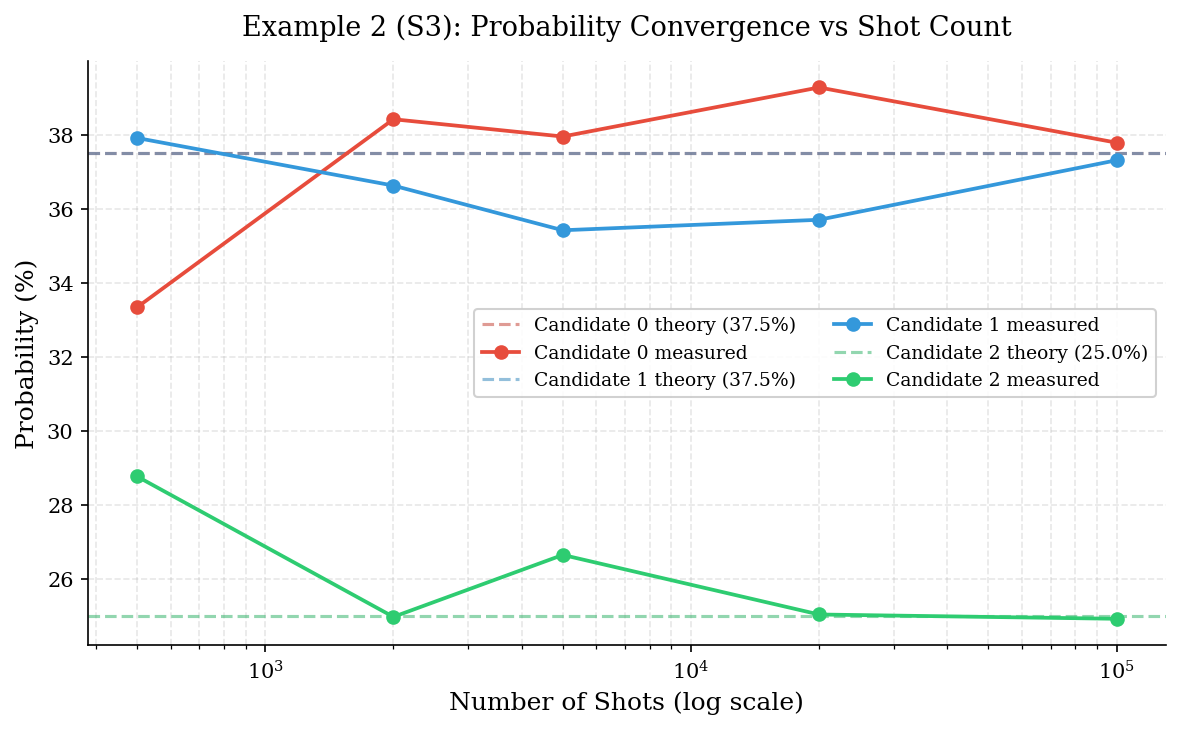

In [12]:
shot_counts_2 = [500, 2_000, 5_000, 20_000, 100_000]
histories_2 = {n: [] for n in proto2.candidate_names}
theo_exact_2 = proto2.theoretical_probabilities

print("Shot Count   │  Cand. 0   │  Cand. 1   │  Cand. 2   │  |C0-C1|")
print("─────────────┼────────────┼────────────┼────────────┼──────────")

for s in shot_counts_2:
    p, v, _ = proto2.run_shots(shots=s)
    for name in proto2.candidate_names:
        histories_2[name].append(p.get(name, 0))
    diff = abs(p.get("Candidate 0", 0) - p.get("Candidate 1", 0)) * 100
    print(f"  {s:>9,}  │  {p.get('Candidate 0',0)*100:7.2f}%  │  "
          f"{p.get('Candidate 1',0)*100:7.2f}%  │  "
          f"{p.get('Candidate 2',0)*100:7.2f}%  │  {diff:5.2f}%")

print("─────────────┼────────────┼────────────┼────────────┼──────────")
tv = [theo_exact_2[n]*100 for n in proto2.candidate_names]
print(f"  Theory     │  {tv[0]:7.2f}%  │  {tv[1]:7.2f}%  │  {tv[2]:7.2f}%  │   0.00%")

fig = plot_convergence(
    shot_counts_2, histories_2, theo_exact_2, proto2.candidate_names,
    title="Example 2 (S3): Probability Convergence vs Shot Count",
    save_path="figures/ex2_s3_convergence.png",
)
plt.show()


---

# Summary

## Ideal Results (Statevector)

| Example | Expected | Measured | Match? |
|---------|----------|----------|--------|
| Ex. 1 (4V, 2C) | P(Blue)=P(Red)=50% | ✅ Exact | ✅ |
| Ex. 2 (8V, 3C) | P(C0)=P(C1)=37.5%, P(C2)=25% | ✅ Exact | ✅ |

## Scenario Observations

| Scenario | Observable Effect |
|----------|-------------------|
| **Noise** | Probability leaks into spoiled states; vote distribution distorted proportional to $p$ |
| **Dishonest Voters** | Significant distortion when ≥25% of voters are dishonest; spoiled votes appear |
| **Convergence** | Tied races require $\sim 10^5$ shots for $<1\%$ error; Hoeffding bound confirmed |

The protocol correctly reproduces the **exact theoretical results** and demonstrates expected degradation under adversarial conditions.
